In [1]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\projects\1\learning\data\kutubxona_v2.sqlite"
conn = sqlite3.connect(DB_PATH)

pd.read_sql("SELECT COUNT(*) AS loans FROM library_loan", conn)

,loans
0,3479


In [2]:
loans = pd.read_sql("SELECT * FROM library_loan", conn)

In [3]:
loans.head()

,id,loan_date,due_date,return_date,book_id,member_id
0,1,2024-12-06,2024-12-20,2024-12-25,25,268
1,2,2024-12-15,2024-12-29,2024-12-23,13,226
2,3,2024-12-16,2024-12-30,2024-12-28,10,226
3,4,2024-12-21,2025-01-04,2025-01-04,22,226
4,5,2024-12-24,2025-01-07,2025-02-03,20,156


In [4]:
loans.dtypes

id             int64
loan_date        str
due_date         str
return_date      str
book_id        int64
member_id      int64
dtype: object

In [5]:
loans.shape

(3479, 6)

In [6]:
pd.read_sql("SELECT COUNT(*) FROM library_member", conn)

,COUNT(*)
0,400


In [7]:
members=pd.read_sql("SELECT * FROM library_member", conn)

In [8]:
loans["loan_date"]=pd.to_datetime(loans["loan_date"])

In [9]:
loans.dtypes

id                      int64
loan_date      datetime64[us]
due_date                  str
return_date               str
book_id                 int64
member_id               int64
dtype: object

In [10]:
loans["loan_month"]=loans["loan_date"].dt.strftime('%Y-%m')

In [11]:
loans.head()

,id,loan_date,due_date,return_date,book_id,member_id,loan_month
0,1,2024-12-06,2024-12-20,2024-12-25,25,268,2024-12
1,2,2024-12-15,2024-12-29,2024-12-23,13,226,2024-12
2,3,2024-12-16,2024-12-30,2024-12-28,10,226,2024-12
3,4,2024-12-21,2025-01-04,2025-01-04,22,226,2024-12
4,5,2024-12-24,2025-01-07,2025-02-03,20,156,2024-12


In [12]:
loans.groupby("loan_month").size()

loan_month
2024-12     12
2025-01     33
2025-02     33
2025-03     47
2025-04     58
2025-05     98
2025-06     72
2025-07     80
2025-08     74
2025-09    132
2025-10    150
2025-11    154
2025-12    166
2026-01    189
2026-02    206
2026-03    238
2026-04    226
2026-05    241
2026-06    173
2026-07    201
2026-08    207
2026-09    269
2026-10    267
2026-11    153
dtype: int64

In [13]:
loans.book_id.value_counts().head(5)

book_id
1     228
7     186
13    183
22    165
29    152
Name: count, dtype: int64

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [15]:
monthly=loans.loc[loans["loan_month"]!='2026-11'].groupby("loan_month").size()

In [16]:
monthly

loan_month
2024-12     12
2025-01     33
2025-02     33
2025-03     47
2025-04     58
2025-05     98
2025-06     72
2025-07     80
2025-08     74
2025-09    132
2025-10    150
2025-11    154
2025-12    166
2026-01    189
2026-02    206
2026-03    238
2026-04    226
2026-05    241
2026-06    173
2026-07    201
2026-08    207
2026-09    269
2026-10    267
dtype: int64

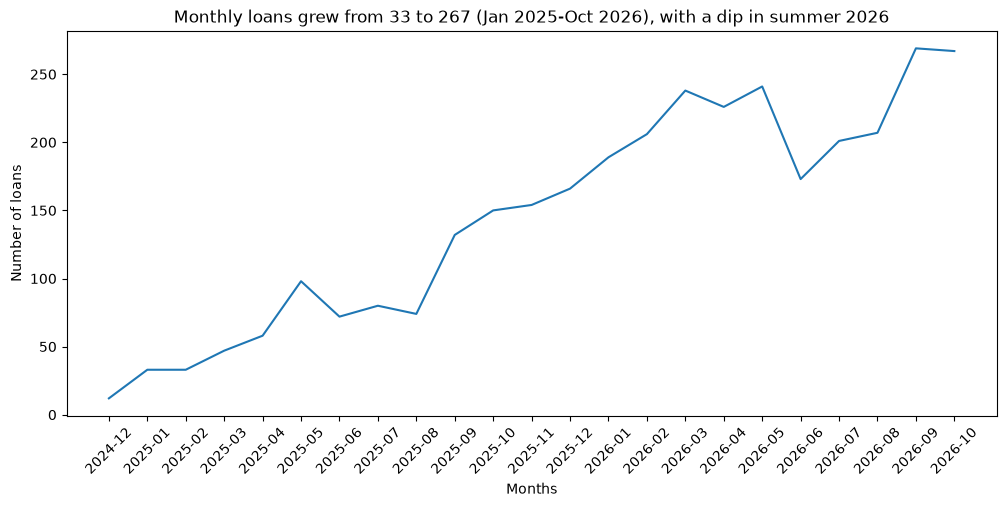

In [17]:
plt.figure(figsize=(12, 5))
plt.title("Monthly loans grew from 33 to 267 (Jan 2025-Oct 2026), with a dip in summer 2026")
sns.lineplot(data=monthly)
plt.xlabel("Months")
plt.xticks(rotation=45)
plt.ylabel("Number of loans")
plt.savefig("images/monthly_loans.png", dpi=150, bbox_inches="tight")

In [18]:
books=pd.read_sql("SELECT * FROM library_book", conn)

In [19]:
top10=loans.book_id.value_counts().head(10).reset_index()

In [20]:
top10_books=pd.merge(top10, books[["id", "title"]], left_on="book_id", right_on="id")

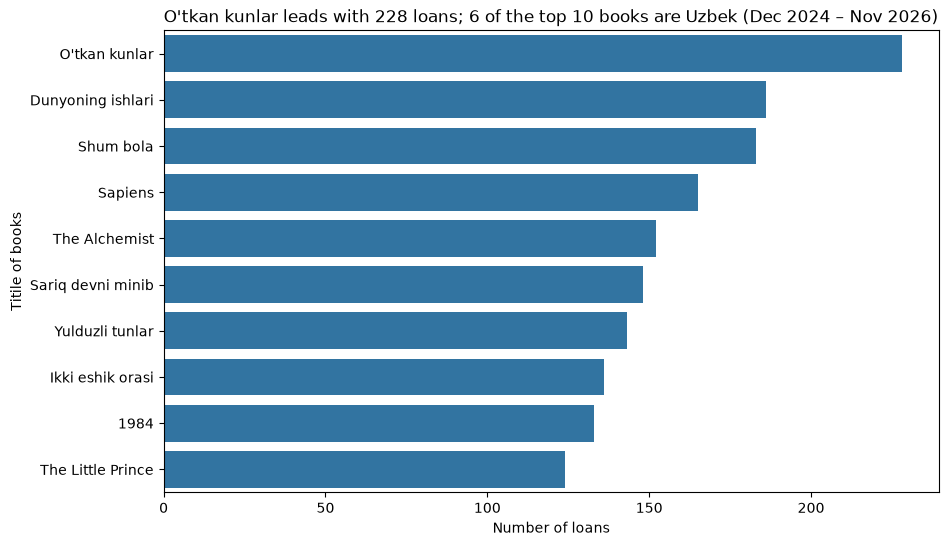

In [21]:
plt.figure(figsize=(10, 6))
plt.title("O'tkan kunlar leads with 228 loans; 6 of the top 10 books are Uzbek (Dec 2024 – Nov 2026)")
sns.barplot(x=top10_books["count"], y=top10_books["title"])
plt.xlabel("Number of loans")
plt.ylabel("Titile of books")
plt.savefig("images/top10_books.png", dpi=150, bbox_inches="tight")